In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
class bsplines:

    def __init__(self, n_basis, degree):

        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(-6, 6, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_y = self.knot_vector.clone()

        # 2D trainable coefficients
        self.coeffs = torch.zeros(n_basis, n_basis, requires_grad=True)

        # 2D input
        # self.x = x

        # Bsplines for the two dimensions
        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:
            ###########Changes##################
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            ###########Changes##################
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x):

        self.B_x =5* torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_y =5* torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_y) for j in range(self.n_basis)])
        y = torch.zeros(x.shape[0])

        # Because we have Dirichlet BC we just omit the first and last bsplines. If we had BC we should put coeff*Bspline in a different loop 
        # they are not trainable parameteres trainable parameters.
        for i in range(1,(self.n_basis-1)):
            for j in range(1,(self.n_basis-1)):
                y += self.coeffs[i, j] * self.B_x[i]*self.B_y[j]
        

        return y

In [3]:
torch.manual_seed(42)
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')

# model = bsplines(10,3)
model = bsplines(20,3)
# model.coeffs.to(device)


In [4]:
torch.manual_seed(42)
colloc_points = 5000
# x = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
# y = torch.linspace(0,0.99,colloc_points, requires_grad=True).reshape(colloc_points,1)
###########Changes#########
# X = 0.999*torch.rand(colloc_points,2)+0.001
X = torch.rand(colloc_points,2)*12-6
##########Changes###########
X.requires_grad_(True)
# X.to(device)

tensor([[ 4.5872,  4.9800],
        [-1.4056,  5.5117],
        [-1.3146,  1.2107],
        ...,
        [ 5.1332,  0.9523],
        [ 3.9698, -3.3829],
        [ 4.9436, -1.0669]], requires_grad=True)

In [5]:
# I had k =0.25 and -2 2
a1=1
a2=1
k=1


In [6]:
X.min()

tensor(-5.9993, grad_fn=<MinBackward1>)

In [6]:
###########Changes#################
# epochs = 6000
epochs = 20000

###########Changes#################
learning_rate=1e-3
# learning_rate=1e-4
###########Changes#################

# Right-hand side of Poisson equation
def f(x, y):
    return (k**2-(a1**2+a2**2)*np.pi ** 2) * torch.sin(a1*np.pi * x) * torch.sin(a2*np.pi * y)

loss_vec = []


###########Changes#################
optimizer = torch.optim.Adam([model.coeffs], lr=learning_rate)
###########Changes#################

for epoch in range(epochs):
    
    ###########Changes#################
    optimizer.zero_grad()
    ###########Changes#################
    u = model.forward(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]

    source = f(X[:,0], X[:,1])
    # Residual loss
    res = u_xx + u_yy +k**2*u - source
    
    loss = torch.mean(res**2)
    
    loss.backward()
    ###########Changes#################
    optimizer.step()
    # # Manually update parameters using the gradients
    # with torch.no_grad():
    #     model.coeffs -= learning_rate * model.coeffs.grad
    # # Zero the gradients after each update
    # model.coeffs.grad.zero_()
    # # x.grad.zero_()
    ###########Changes#################

    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/20000], Loss: 80.4773178100586
Epoch [10/20000], Loss: 73.4065170288086
Epoch [15/20000], Loss: 66.9708023071289
Epoch [20/20000], Loss: 61.14892578125
Epoch [25/20000], Loss: 55.900882720947266
Epoch [30/20000], Loss: 51.18080139160156
Epoch [35/20000], Loss: 46.94190216064453
Epoch [40/20000], Loss: 43.13588333129883
Epoch [45/20000], Loss: 39.714942932128906
Epoch [50/20000], Loss: 36.634124755859375
Epoch [55/20000], Loss: 33.85347366333008
Epoch [60/20000], Loss: 31.337718963623047
Epoch [65/20000], Loss: 29.056161880493164
Epoch [70/20000], Loss: 26.982452392578125
Epoch [75/20000], Loss: 25.093950271606445
Epoch [80/20000], Loss: 23.371206283569336
Epoch [85/20000], Loss: 21.797401428222656
Epoch [90/20000], Loss: 20.357898712158203
Epoch [95/20000], Loss: 19.03990936279297
Epoch [100/20000], Loss: 17.832277297973633
Epoch [105/20000], Loss: 16.725204467773438
Epoch [110/20000], Loss: 15.71004867553711
Epoch [115/20000], Loss: 14.779125213623047
Epoch [120/20000], Loss:

KeyboardInterrupt: 

In [20]:
# Transform list of tensors to numpy array
loss_vec_npy = np.array(loss_vec)
np.save('./results/Helmotz/bsplines_loss_6.npy',loss_vec_npy)

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs }
torch.save(params,'./results/Helmotz/model_bsplines_6.pth')

In [7]:
# Load model trainable parameters
model_s = bsplines(25,4)
loaded_params = torch.load('./results/Helmotz/model_bsplines_6.pth')
model_s.coeffs = loaded_params['coeffs_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_91724\3324454358.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/Helmotz/model_bspl

In [7]:
model_s.coeffs

tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904, 0.6009, 0.2566, 0.7936, 0.9408,
         0.1332, 0.9346, 0.5936, 0.8694, 0.5677, 0.7411, 0.4294, 0.8854, 0.5739,
         0.2666, 0.6274],
        [0.2696, 0.0038, 0.0114, 0.0224, 0.0326, 0.0417, 0.0494, 0.0555, 0.0596,
         0.0617, 0.0617, 0.0596, 0.0555, 0.0494, 0.0417, 0.0326, 0.0224, 0.0114,
         0.0038, 0.3423],
        [0.6343, 0.0114, 0.0341, 0.0671, 0.0978, 0.1252, 0.1483, 0.1664, 0.1788,
         0.1851, 0.1851, 0.1788, 0.1664, 0.1483, 0.1252, 0.0978, 0.0671, 0.0341,
         0.0114, 0.1447],
        [0.5315, 0.0224, 0.0671, 0.1320, 0.1924, 0.2461, 0.2916, 0.3271, 0.3514,
         0.3638, 0.3638, 0.3514, 0.3271, 0.2916, 0.2462, 0.1924, 0.1320, 0.0671,
         0.0224, 0.9155],
        [0.2418, 0.0326, 0.0978, 0.1924, 0.2803, 0.3587, 0.4249, 0.4767, 0.5121,
         0.5302, 0.5302, 0.5122, 0.4766, 0.4249, 0.3587, 0.2803, 0.1924, 0.0978,
         0.0326, 0.0162],
        [0.2137, 0.0417, 0.1252, 0.2462, 0.3587, 0.4591, 0.5

In [7]:
loss_bsplines_s = np.load('./results/Helmotz/bsplines_loss_6.npy')

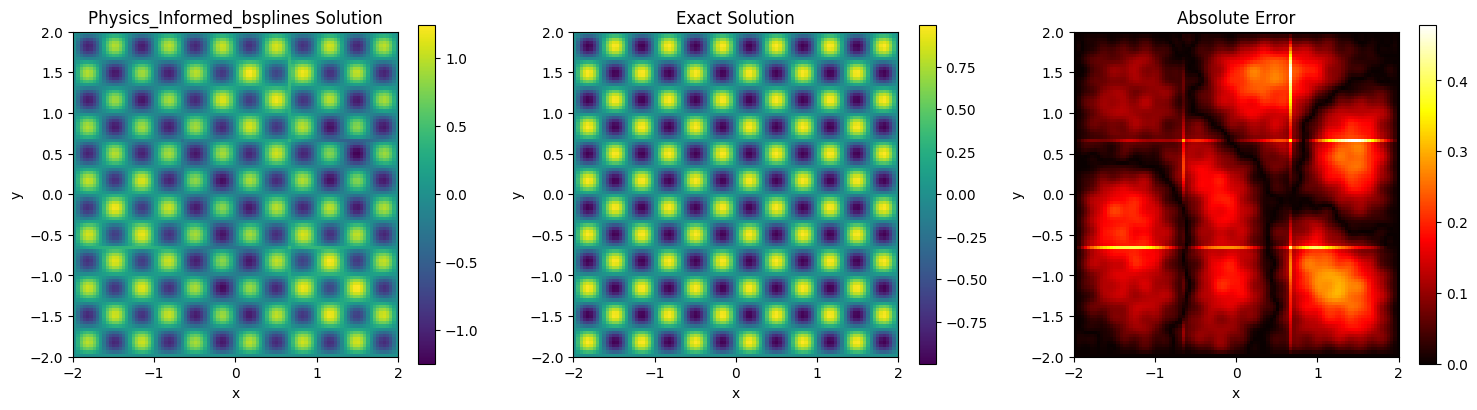

In [8]:
x = y = np.linspace(-6, 6, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
with torch.no_grad():
    u_pred = model_s.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

u_exact = np.sin(a1*np.pi * Xg) * np.sin(a2*np.pi * Yg)

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[-2,2,-2,2], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[-2,2,-2,2], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[-2,2,-2,2], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

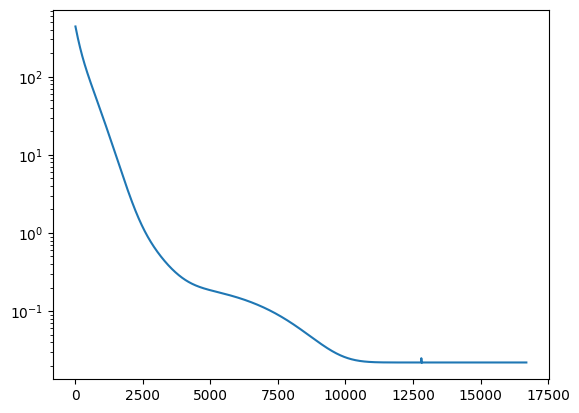

In [14]:
plt.plot(loss_vec)
plt.yscale('log')

PINN for 2D poisson equation

In [13]:
k=1
a1=1
a2=1

In [2]:

# First we are implementing hyperparameter tuning based on optuna with Tree-structured Parzen Estimator (TPE) algorithm.

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import optuna
import random
torch.manual_seed(42)
# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    # Force deterministic behavior in CuDNN (can slow training)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
# PINN model
# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"layer{i}", nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh{i}", nn.Tanh())

    def forward(self, x):
        return self.net(x)

# Right-hand side of Poisson equation
def f(x, y):
    return (k**2-(a1**2+a2**2)*np.pi ** 2) * torch.sin(a1*np.pi * x) * torch.sin(a2*np.pi * y)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]
    source = f(X[:,0], X[:,1])
    # Residual loss
    res = u_xx + u_yy +k**2*u - source
    return torch.mean((res)**2)

# Boundary loss
def boundary_loss(model, Xb):
    return torch.mean(model(Xb)**2)

# Generate collocation and boundary points
def generate_points(n_interior, n_boundary):
    # Interior points
    xy_in = (torch.rand(n_interior, 2)*4-2).to(device)
    # Boundary points on [-2,2]^2
    lin = torch.linspace(-2, 2, n_boundary).unsqueeze(1)
    zero = -2*torch.ones_like(lin)
    one = 2*torch.ones_like(lin)
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b = torch.cat([b1, b2, b3, b4], dim=0).to(device)
    return xy_in, xy_b

# Train the model
# layers = [2, 20, 20, 20, 1]
# model = PINN(layers).to(device)
# optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# X_in, X_b = generate_points(5000, 1000)


# Hyperparameter tuning 

def objective(trial):
    # Sample hyperparameters
    n_layers = trial.suggest_int("n_layers", 2, 5)
    n_neurons = trial.suggest_int("n_neurons", 10, 100)
    learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)

    # Build layers list
    layers = [2] + [n_neurons] * n_layers + [1]
    model = PINN(layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Generate training data
    X_in, X_b = generate_points(5000, 1000)  # reduced size for faster tuning

    # Train for a small number of epochs
    for epoch in range(1000):
        optimizer.zero_grad()
        loss_in = pde_loss(model, X_in)
        loss_b = boundary_loss(model, X_b)
        loss = loss_in + loss_b
        loss.backward()
        optimizer.step()

    return loss.item()

# ---- Run Optuna study ---- #
if __name__ == "__main__":
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=20)

    print("Best trial:")
    trial = study.best_trial
    print(f"  Loss: {trial.value}")
    print("  Best hyperparameters:")
    for key, value in trial.params.items():
        print(f"    {key}: {value}")

c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2025-07-16 18:24:48,038] A new study created in memory with name: no-name-dcf3a181-f852-48cb-9122-dfce4431c2f2
C:\Users\Polydoras\AppData\Local\Temp\ipykernel_28952\460406910.py:90: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  learning_rate = trial.suggest_loguniform("lr", 1e-4, 1e-2)
c:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines\.venv\lib\site-packages\torch\autograd\graph.py:769: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work

Best trial:
  Loss: 0.23473481833934784
  Best hyperparameters:
    n_layers: 3
    n_neurons: 96
    lr: 0.0029106359131330704


Now train the PINN by applying the hyperparameters after the tuning 

In [14]:
k=1
a1=1
a2=1

In [19]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
torch.manual_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device( 'cpu')

# PINN model
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.net = nn.Sequential()
        for i in range(len(layers) - 1):
            self.net.add_module(f"layer{i}", nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                self.net.add_module(f"tanh{i}", nn.Tanh())

    def forward(self, x):
        return self.net(x)

In [20]:


# Right-hand side of Poisson equation
def f(x, y):
    return (k**2-(a1**2+a2**2)*np.pi ** 2) * torch.sin(a1*np.pi * x) * torch.sin(a2*np.pi * y)

# PDE residual
def pde_loss(model, X):
    X.requires_grad_(True)
    u = model(X)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_y = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_yy = torch.autograd.grad(u_y, X, torch.ones_like(u_y), create_graph=True)[0][:, 1]
    source = f(X[:,0], X[:,1])
    # Residual loss
    res = u_xx + u_yy +k**2*u - source
    return torch.mean((res)**2)

# Boundary loss
def boundary_loss(model, Xb):
    return torch.mean(model(Xb)**2)

# Generate collocation and boundary points
def generate_points(n_interior, n_boundary):
    # Interior points
    xy_in = (torch.rand(n_interior, 2)*12-6).to(device)
    # Boundary points on [-2,2]^2
    lin = torch.linspace(-6, 6, n_boundary).unsqueeze(1)
    zero = -6*torch.ones_like(lin)
    one = 6*torch.ones_like(lin)
    b1 = torch.cat([lin, zero], dim=1)
    b2 = torch.cat([lin, one], dim=1)
    b3 = torch.cat([zero, lin], dim=1)
    b4 = torch.cat([one, lin], dim=1)
    xy_b = torch.cat([b1, b2, b3, b4], dim=0).to(device)
    return xy_in, xy_b

# Train the model
###########Changes############
# layers = [2, 20, 20, 20, 1]
# layers = [2, 64, 64, 1]
layers = [2, 96, 96, 96, 1]
###########Changes############

model = PINN(layers).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

###########Changes############
X_in, X_b = generate_points(5000, 1000)
# X_in, X_b = generate_points(5000, 50)
###########Changes############
loss_vec = []
for epoch in range(80000):

    optimizer.zero_grad()

    loss_in = pde_loss(model, X_in)
    loss_b = boundary_loss(model, X_b)
    loss = loss_in + loss_b

    loss.backward()
    optimizer.step()

    loss_vec.append(loss.item())
    if epoch % 300 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")
    # if epoch==0:
    #     break  




Epoch 0, Loss: 87.332611
Epoch 300, Loss: 78.778023
Epoch 600, Loss: 63.376534
Epoch 900, Loss: 54.179493
Epoch 1200, Loss: 48.992924
Epoch 1500, Loss: 43.854130
Epoch 1800, Loss: 39.273773
Epoch 2100, Loss: 35.240086
Epoch 2400, Loss: 31.350416
Epoch 2700, Loss: 27.911110
Epoch 3000, Loss: 24.782234
Epoch 3300, Loss: 21.707218
Epoch 3600, Loss: 18.484682
Epoch 3900, Loss: 15.814398
Epoch 4200, Loss: 13.177479
Epoch 4500, Loss: 10.623431
Epoch 4800, Loss: 8.774012
Epoch 5100, Loss: 7.310350
Epoch 5400, Loss: 5.998213
Epoch 5700, Loss: 5.068602
Epoch 6000, Loss: 4.336027
Epoch 6300, Loss: 3.736658
Epoch 6600, Loss: 3.168621
Epoch 6900, Loss: 2.561714
Epoch 7200, Loss: 2.048157
Epoch 7500, Loss: 1.668629
Epoch 7800, Loss: 1.367102
Epoch 8100, Loss: 1.131356
Epoch 8400, Loss: 0.957485
Epoch 8700, Loss: 0.825739
Epoch 9000, Loss: 0.714512
Epoch 9300, Loss: 0.624733
Epoch 9600, Loss: 0.558288
Epoch 9900, Loss: 0.507742
Epoch 10200, Loss: 0.464297
Epoch 10500, Loss: 0.426551
Epoch 10800, Los

KeyboardInterrupt: 

In [7]:
# Transform list of tensors to numpy array
loss_vec_npy = np.array(loss_vec)
np.save('./results/Helmotz/pinn_loss.npy',loss_vec_npy)


In [8]:
#Save model trainable parameters
torch.save(model.state_dict(), './results/Helmotz/model_pinn.pth')

In [8]:
layers = [2, 100, 100,100, 1]
model_s = PINN(layers)  # same architecture as used before
model_s.load_state_dict(torch.load('./results/Helmotz/model_pinn.pth'))
model_s.eval()  # if you're evaluating


C:\Users\Polydoras\AppData\Local\Temp\ipykernel_6628\1493406577.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_s.load_state_dict(torch.load('./results/Helmotz/mod

PINN(
  (net): Sequential(
    (layer0): Linear(in_features=2, out_features=100, bias=True)
    (tanh0): Tanh()
    (layer1): Linear(in_features=100, out_features=100, bias=True)
    (tanh1): Tanh()
    (layer2): Linear(in_features=100, out_features=100, bias=True)
    (tanh2): Tanh()
    (layer3): Linear(in_features=100, out_features=1, bias=True)
  )
)

In [10]:
loss_pinn = np.load('./results/Helmotz/pinn_loss.npy')

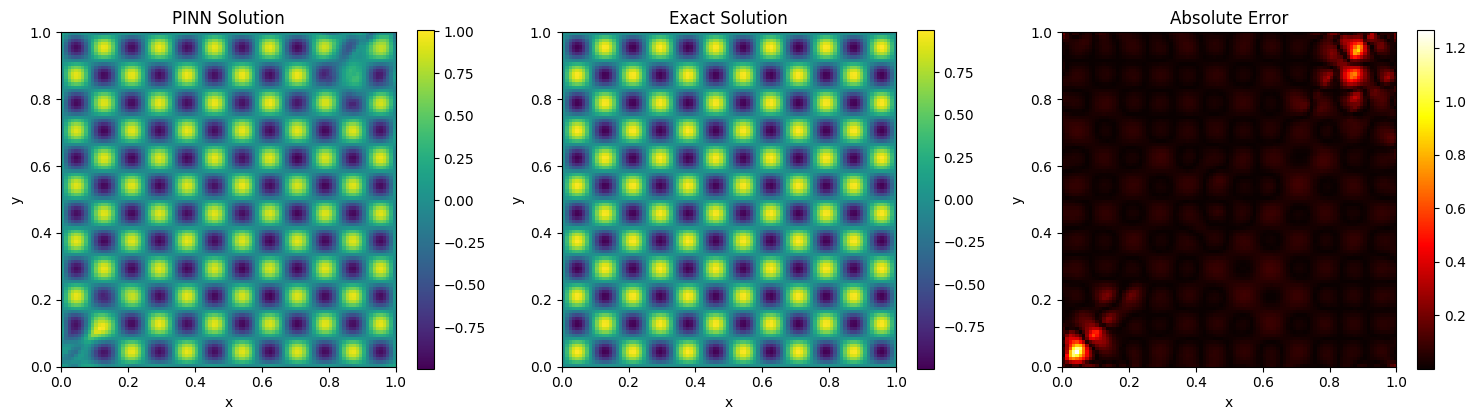

In [21]:
x = y = np.linspace(-6, 6, 100)
Xg, Yg = np.meshgrid(x, y)
XY = np.vstack([Xg.ravel(), Yg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
model.cpu()
u_exact = np.sin(a1*np.pi * Xg) * np.sin(a2*np.pi * Yg)
with torch.no_grad():
    u_pred = model.forward(XY_torch).numpy().reshape(Xg.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 4))

# PINN solution
im0 = axs[0].imshow(u_pred, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("PINN Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exact, extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = np.abs(u_pred - u_exact)
im2 = axs[2].imshow(error, extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

Text(0, 0.5, 'loss')

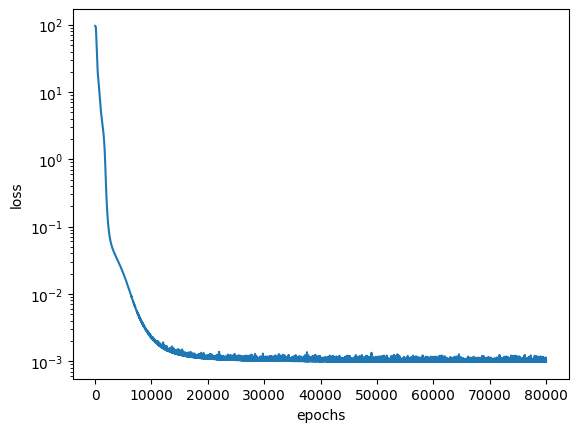

In [11]:

plt.plot(loss_pinn)
plt.yscale("log")
plt.xlabel("epochs")
plt.ylabel("loss")